# 📣 Digital Advertising Campaign Analytics
### A reproducible end-to-end exploratory data analysis

This notebook follows the course exercises and extends them with **weighted KPIs, targeting cohorts, campaign economics, and data-quality checks**.

**Dataset:** `conversion.csv` (1,143 ad-level records). No revenue, dates, or currency label are provided. Outcomes are observational — no A/B inference.

**Portfolio flow:** inspect → validate → visualize → engineer metrics → benchmark → audit → derive cautiously stated business insights.


## 1. Setup and load data
Run from the repository root. The raw CSV is included in the downloadable archive but intentionally excluded from Git commits until redistribution permission is confirmed.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src.analysis import load_ads, add_ad_metrics, group_summary, overall_summary, quality_report

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
DATA = ROOT / "data/raw/conversion.csv"
conversion = load_ads(DATA)
conversion.head()

,ad_id,xyz_campaign_id,fb_campaign_id,age,gender,interest,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion
0,708746,916,103916,30-34,M,15,7350,1,1.43,2,1
1,708749,916,103917,30-34,M,16,17861,2,1.82,2,0
2,708771,916,103920,30-34,M,20,693,0,0.00,1,0
3,708815,916,103928,30-34,M,28,4259,1,1.25,1,0
4,708818,916,103928,30-34,M,28,4133,1,1.29,1,1


## 2. Initial exploratory checks

In [2]:
print("Rows / columns:", conversion.shape)
print("Duplicate rows:", conversion.duplicated().sum())
print("Missing values per column:")
print(conversion.isna().sum().to_string())
print("\nDtypes:")
print(conversion.dtypes.to_string())

Rows / columns: (1143, 11)
Duplicate rows: 0
Missing values per column:
ad_id                  0
xyz_campaign_id        0
fb_campaign_id         0
age                    0
gender                 0
interest               0
Impressions            0
Clicks                 0
Spent                  0
Total_Conversion       0
Approved_Conversion    0

Dtypes:
ad_id                    int64
xyz_campaign_id          int64
fb_campaign_id           int64
age                     object
gender                  object
interest                 int64
Impressions              int64
Clicks                   int64
Spent                  float64
Total_Conversion         int64
Approved_Conversion      int64


### Variable types
- Discrete counts: impressions, clicks, total conversions, approved purchases.
- Continuous: spend (recorded in monetary units).
- Nominal: gender, interest codes, ad/campaign IDs.
- Ordinal: age category (not individual age).

## 3. Campaign counts and impression distributions

Unique XYZ campaign IDs: 3
xyz_campaign_id
916      54
936     464
1178    625
Name: count, dtype: int64


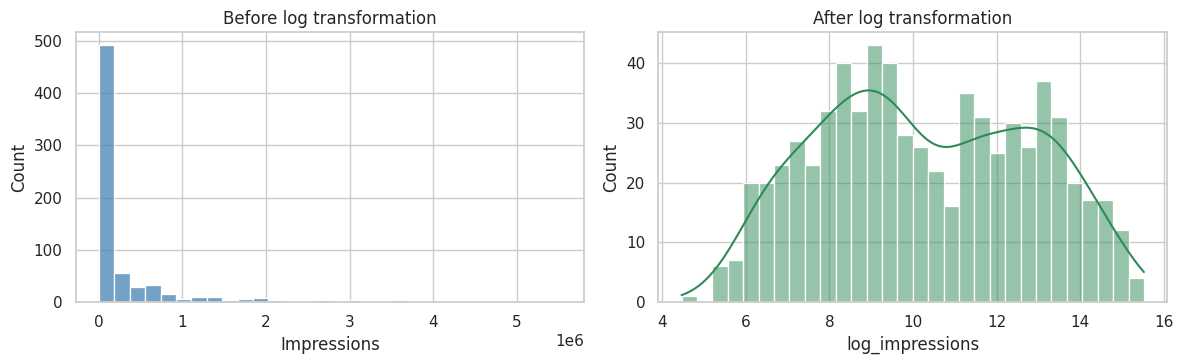

In [3]:
print("Unique XYZ campaign IDs:", conversion.xyz_campaign_id.nunique())
print(conversion.xyz_campaign_id.value_counts().sort_index())
fb = conversion.groupby('fb_campaign_id', as_index=False)['Impressions'].sum()
fb['log_impressions'] = np.log(fb['Impressions'].clip(lower=1))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(data=fb, x='Impressions', bins=30, ax=axes[0], color='steelblue')
sns.histplot(data=fb, x='log_impressions', bins=30, kde=True, ax=axes[1], color='seagreen')
axes[0].set_title('Before log transformation')
axes[1].set_title('After log transformation')
plt.tight_layout()
plt.show()

## 4. Course metrics: CTR, CPC, and click-to-purchase conversion

In [4]:
ads = add_ad_metrics(conversion)
columns=['ad_id','xyz_campaign_id','ctr','cpc','click_to_purchase_rate','cost_per_purchase']
display(ads[columns].head())
print('Highest CTR ad:', int(ads.loc[ads.ctr.idxmax(),'ad_id']))
print('CPC IQR:', round(ads.cpc.quantile(.75)-ads.cpc.quantile(.25),4))
print('Ad 1121814 click-to-purchase conversion %:',
      round(ads.loc[ads.ad_id==1121814,'click_to_purchase_rate'].iloc[0]*100,2))

,ad_id,xyz_campaign_id,ctr,cpc,click_to_purchase_rate,cost_per_purchase
0,708746,916,0.000136,1.43,1.0,1.43
1,708749,916,0.000112,0.91,0.0,NaN
2,708771,916,0.000000,NaN,NaN,NaN
3,708815,916,0.000235,1.25,0.0,NaN
4,708818,916,0.000242,1.29,1.0,1.29


Highest CTR ad: 738637
CPC IQR: 0.2544
Ad 1121814 click-to-purchase conversion %: 3.09


**Important:** a rate cannot be evaluated when its denominator equals zero. Such results appear as `NaN`, not as zero. Aggregated ratios are computed from the sums of numerators and denominators, to prevent unequal ad sizes from distorting rates.

## 5. CTR distributions by campaign

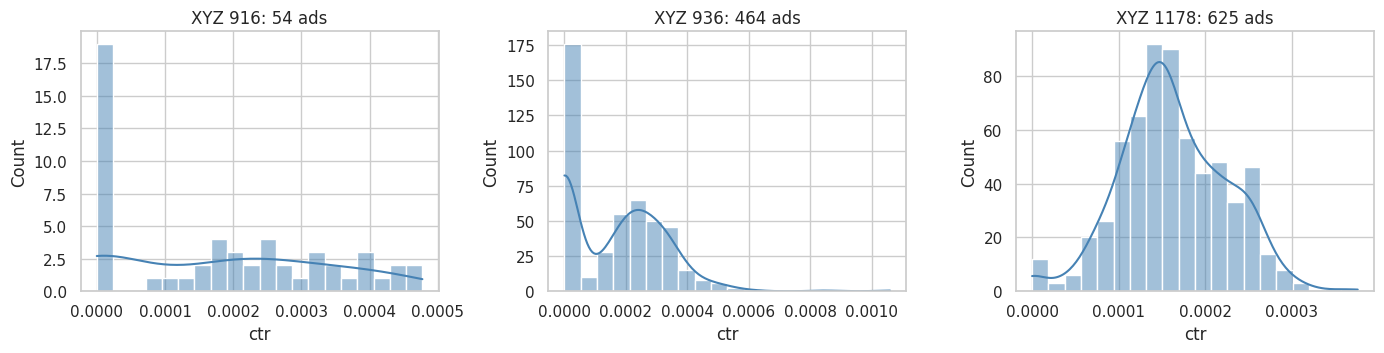

In [5]:
fig,axes=plt.subplots(1,3,figsize=(14,3.7),sharex=False)
for ax,(campaign,group) in zip(axes,ads.groupby('xyz_campaign_id')):
    sns.histplot(data=group, x='ctr', bins=20, kde=True, ax=ax, color='steelblue')
    ax.set_title(f'XYZ {campaign}: {len(group)} ads')
plt.tight_layout(); plt.show()

## 6. CPC by audience gender

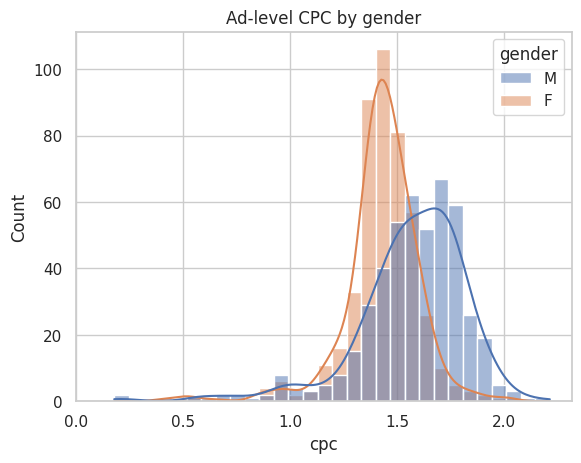

In [6]:
sns.histplot(data=ads, x='cpc', hue='gender', bins=30, kde=True)
plt.title('Ad-level CPC by gender')
plt.xlim(left=0)
plt.show()

## 7. Weighted KPI summary (additional portfolio analysis)

In [7]:
summary=overall_summary(conversion)
display(pd.Series(summary, name='Value').to_frame())
by_campaign=group_summary(conversion,'xyz_campaign_id')
display(by_campaign.round(5))

,Value
ads,1.143000e+03
campaigns,3.000000e+00
impressions,2.134348e+08
clicks,3.816500e+04
spent,5.870523e+04
interested,3.264000e+03
purchases,1.079000e+03
ctr,1.788134e-04
cpc,1.538195e+00
click_to_purchase_rate,2.827198e-02


,xyz_campaign_id,ads,impressions,clicks,spent,interested,purchases,ctr,cpc,click_to_purchase_rate,cost_per_purchase
0,916,54,482925,113,149.71000,58,24,0.00023,1.32487,0.21239,6.23792
1,936,464,8128187,1984,2893.37000,537,183,0.00024,1.45835,0.09224,15.81077
2,1178,625,204823716,36068,55662.14996,2669,872,0.00018,1.54326,0.02418,63.83274


Campaign impressions, clicks and spends differ substantially. **Do not** compare campaigns by raw purchases alone when discussing efficiency; compare spend per approved purchase alongside sample sizes. Economic profitability cannot be measured because revenue is missing.

## 8. Campaign comparisons

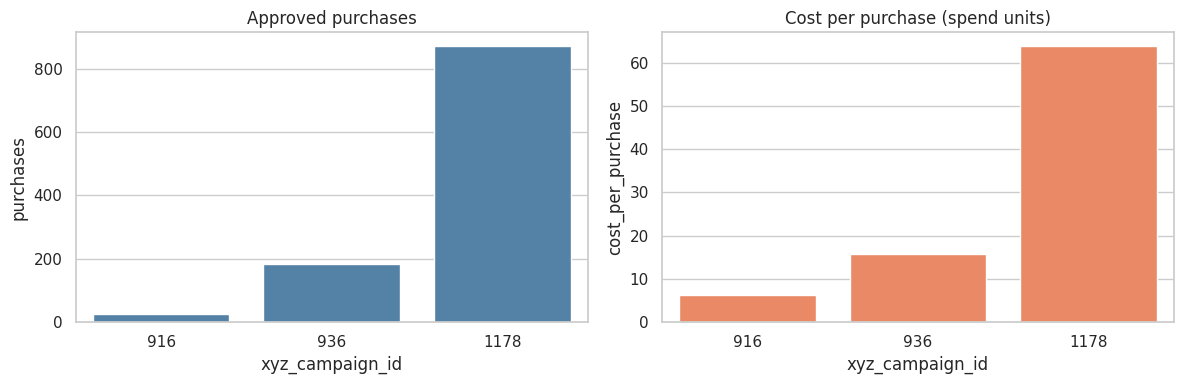

In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=by_campaign,x='xyz_campaign_id',y='purchases',ax=axes[0],color='steelblue')
sns.barplot(data=by_campaign,x='xyz_campaign_id',y='cost_per_purchase',ax=axes[1],color='coral')
axes[0].set_title('Approved purchases')
axes[1].set_title('Cost per purchase (spend units)')
plt.tight_layout();plt.show()

## 9. Age & gender targeting analysis

,age,gender,ads,impressions,clicks,spent,interested,purchases,ctr,cpc,click_to_purchase_rate,cost_per_purchase
1,30-34,M,229,36421443,4384,7640.92,812,299,0.0001,1.7429,0.0682,25.5549
0,30-34,F,197,31571576,5099,7611.48,619,195,0.0002,1.4927,0.0382,39.0332
3,35-39,M,139,20665139,2933,5051.08,322,112,0.0001,1.7222,0.0382,45.0989
6,45-49,F,138,38455591,9441,13433.21,399,112,0.0002,1.4229,0.0119,119.9394
7,45-49,M,121,25277267,4411,7317.46,285,96,0.0002,1.6589,0.0218,76.2235
2,35-39,F,109,21439505,4161,6061.35,304,95,0.0002,1.4567,0.0228,63.8037
4,40-44,F,107,23396175,5177,7396.58,322,93,0.0002,1.4287,0.0180,79.5331
5,40-44,M,103,16208132,2559,4193.15,201,77,0.0002,1.6386,0.0301,54.4565


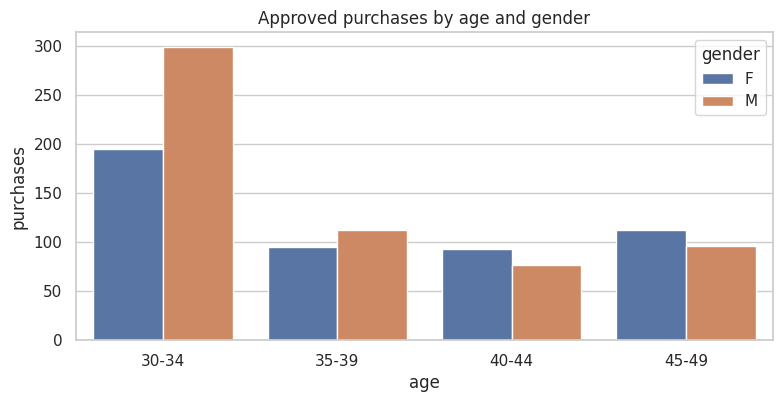

In [9]:
by_segment=group_summary(conversion,['age','gender'])
display(by_segment.sort_values('purchases',ascending=False).round(4))
plt.figure(figsize=(9,4))
sns.barplot(data=by_segment,x='age',y='purchases',hue='gender')
plt.title('Approved purchases by age and gender')
plt.show()

## 10. Interest segments and minimum sample size

In [10]:
by_interest=group_summary(conversion,'interest')
min_clicks = 30
reliable = by_interest.query('clicks >= @min_clicks').sort_values('purchases',ascending=False)
display(reliable.head(10).round(4))

,interest,ads,impressions,clicks,spent,interested,purchases,ctr,cpc,click_to_purchase_rate,cost_per_purchase
4,16,140,31809524,5144,8084.91,411,141,0.0002,1.5717,0.0274,57.3398
16,29,77,18768653,3315,5045.19,306,132,0.0002,1.5219,0.0398,38.2211
2,10,85,17989844,3317,5086.38,269,91,0.0002,1.5334,0.0274,55.8943
3,15,51,10745856,1609,2597.26,195,63,0.0001,1.6142,0.0392,41.2263
14,27,60,16352527,3409,5176.17,240,54,0.0002,1.5184,0.0158,95.8550
7,20,49,6899907,1234,1960.77,129,47,0.0002,1.5890,0.0381,41.7185
15,28,51,10959830,2025,3205.85,146,42,0.0002,1.5831,0.0207,76.3298
19,32,33,6455261,1138,1970.53,76,35,0.0002,1.7316,0.0308,56.3009
21,63,46,8365640,1675,2484.06,101,34,0.0002,1.4830,0.0203,73.0606
5,18,43,8646488,1524,2425.07,85,33,0.0002,1.5913,0.0217,73.4870


## 11. Data quality (important caveat)

In [11]:
display(pd.Series(quality_report(conversion),name='value').to_frame())
print('Problematic example rows:')
display(conversion.loc[conversion.Approved_Conversion>conversion.Clicks,
    ['ad_id','xyz_campaign_id','Clicks','Approved_Conversion']].head(8))

,value
rows,1143
duplicates,0
missing_cells,0
zero_click_ads,207
purchases_gt_clicks,72
purchases_with_zero_clicks,71
interests_gt_clicks,218
negative_metrics,0


Problematic example rows:


,ad_id,xyz_campaign_id,Clicks,Approved_Conversion
5,708820,916,0,1
15,709105,916,0,1
17,709124,916,0,1
20,709320,916,0,1
24,709328,916,0,1
30,709899,916,0,1
35,710477,916,0,1
53,712052,916,0,1


**Interpretation:** some rows report purchases without clicks or more purchases than clicks. This is inconsistent with a strictly nested, unique-user click → purchase funnel and may reflect source definitions, attribution or data errors. We retain those records but label `purchases/clicks` as a **descriptive aggregated ratio** rather than a verified person-level probability. We cannot infer causality, ROAS, or temporal trends.

## 12. Portfolio takeaways

In [12]:
by_campaign=by_campaign.sort_values('xyz_campaign_id')
lowest=by_campaign.loc[by_campaign.cost_per_purchase.idxmin()]
largest=by_campaign.loc[by_campaign.purchases.idxmax()]
print(f"Most approved purchases: campaign {int(largest.xyz_campaign_id)} with {int(largest.purchases):,} purchases.")
print(f"Lowest observed cost/purchase: campaign {int(lowest.xyz_campaign_id)} at {lowest.cost_per_purchase:.2f} spend units.")
print("Further analysis needs purchase revenue, timestamps and conversion attribution definitions.")

Most approved purchases: campaign 1178 with 872 purchases.
Lowest observed cost/purchase: campaign 916 at 6.24 spend units.
Further analysis needs purchase revenue, timestamps and conversion attribution definitions.


### Reproducibility and limitations
- `python scripts/generate_report.py` regenerates the static visualizations and executive report.
- `streamlit run app.py` opens a filterable dashboard.
- `python -m pytest -q` verifies metric calculations on synthetic edge cases.
- Source CSV redistribution rights are **not independently verified**; the public repository should not include the original raw file without permission.
- Published demo data is explicitly **synthetic**, not a substitute for real results.
